In [8]:

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

In [5]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [7]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [9]:
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode_values = df[col].mode()
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values[0])

df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

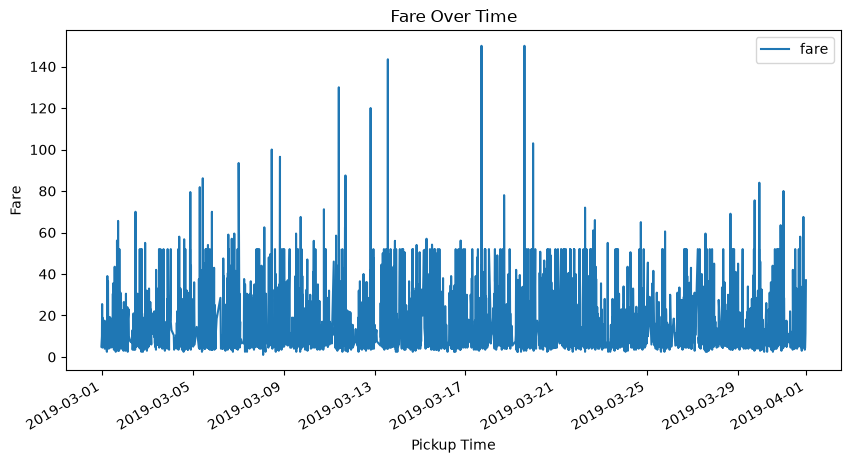

In [10]:
df["pickup"] = pd.to_datetime(df["pickup"])

df.sort_values("pickup").plot(
    x="pickup", y="fare",
    kind="line", figsize=(10, 5)
)

plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.show()

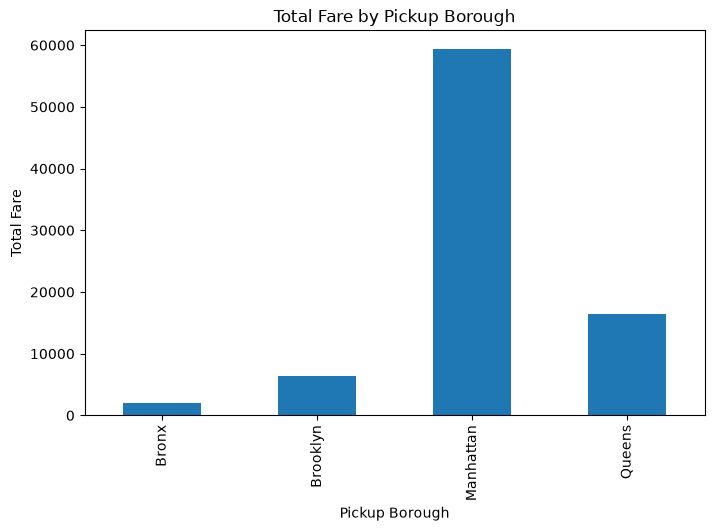

In [11]:
df.groupby("pickup_borough")["fare"].sum().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.show()

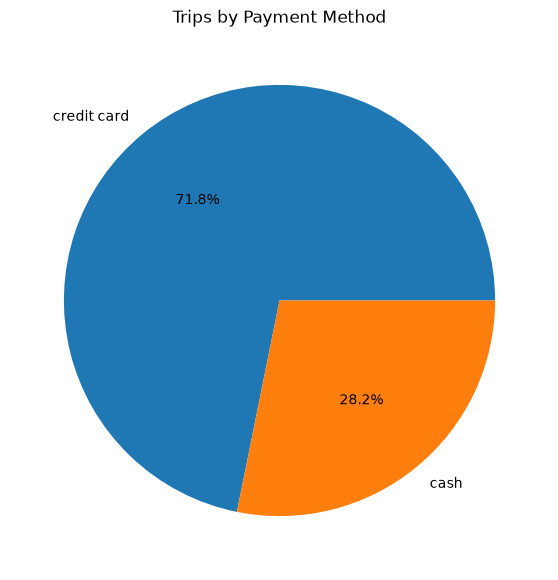

In [12]:
df["payment"].value_counts().plot(
    kind="pie", autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Trips by Payment Method")
plt.ylabel("")
plt.show()

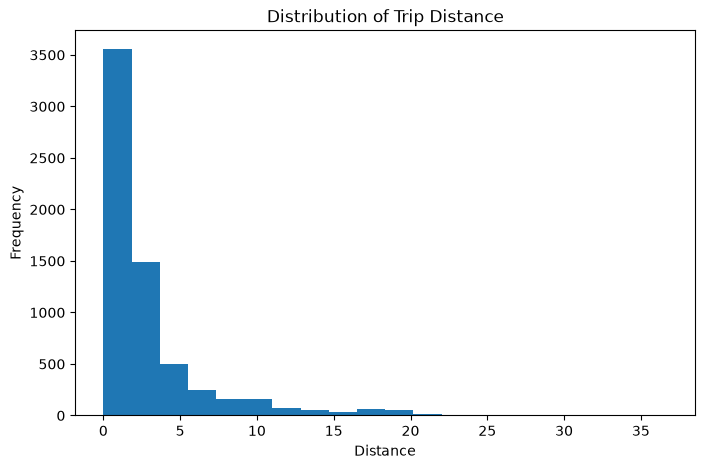

In [13]:
df["distance"].plot(
    kind="hist", bins=20, figsize=(8, 5)
)

plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.show()

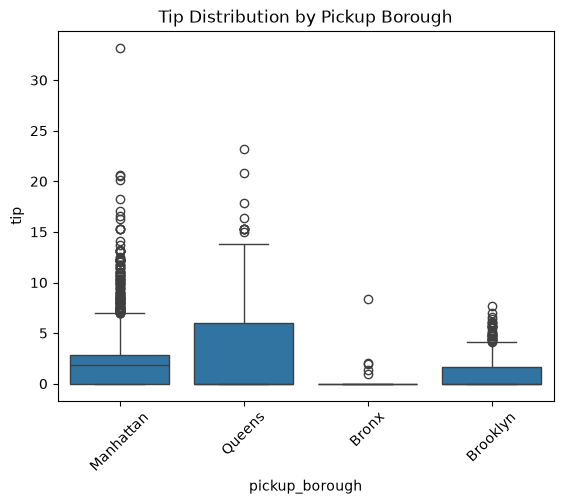

In [14]:
sns.boxplot(data=df, x="pickup_borough", y="tip")

plt.title("Tip Distribution by Pickup Borough")
plt.xticks(rotation=45)
plt.show()

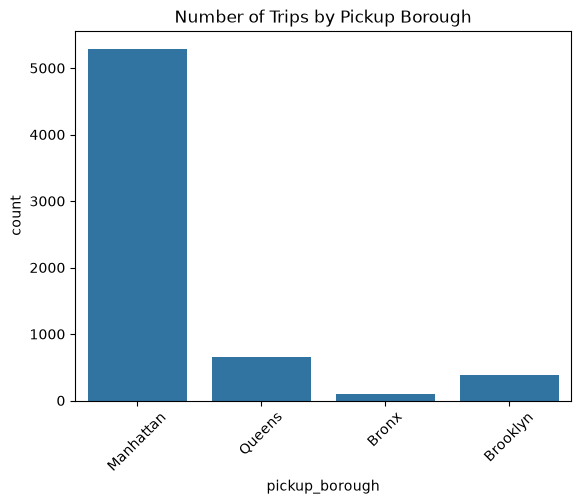

In [15]:
sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xticks(rotation=45)
plt.show()

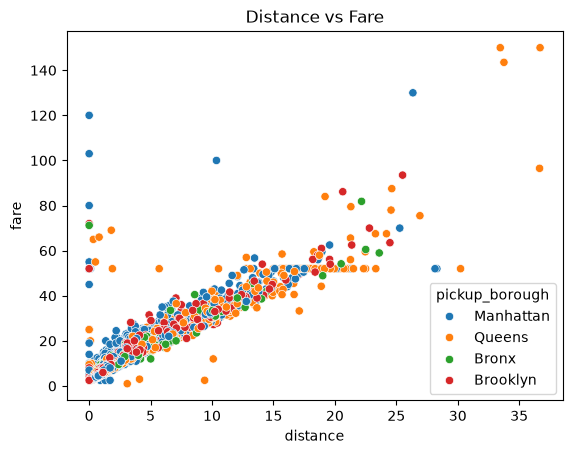

In [16]:
sns.scatterplot(
    data=df, x="distance", y="fare",
    hue="pickup_borough"
)

plt.title("Distance vs Fare")
plt.show()

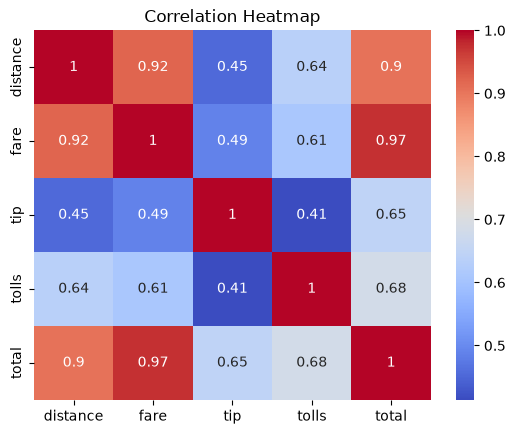

In [17]:
numeric_cols = ["distance", "fare", "tip", "tolls", "total"]

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True, cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

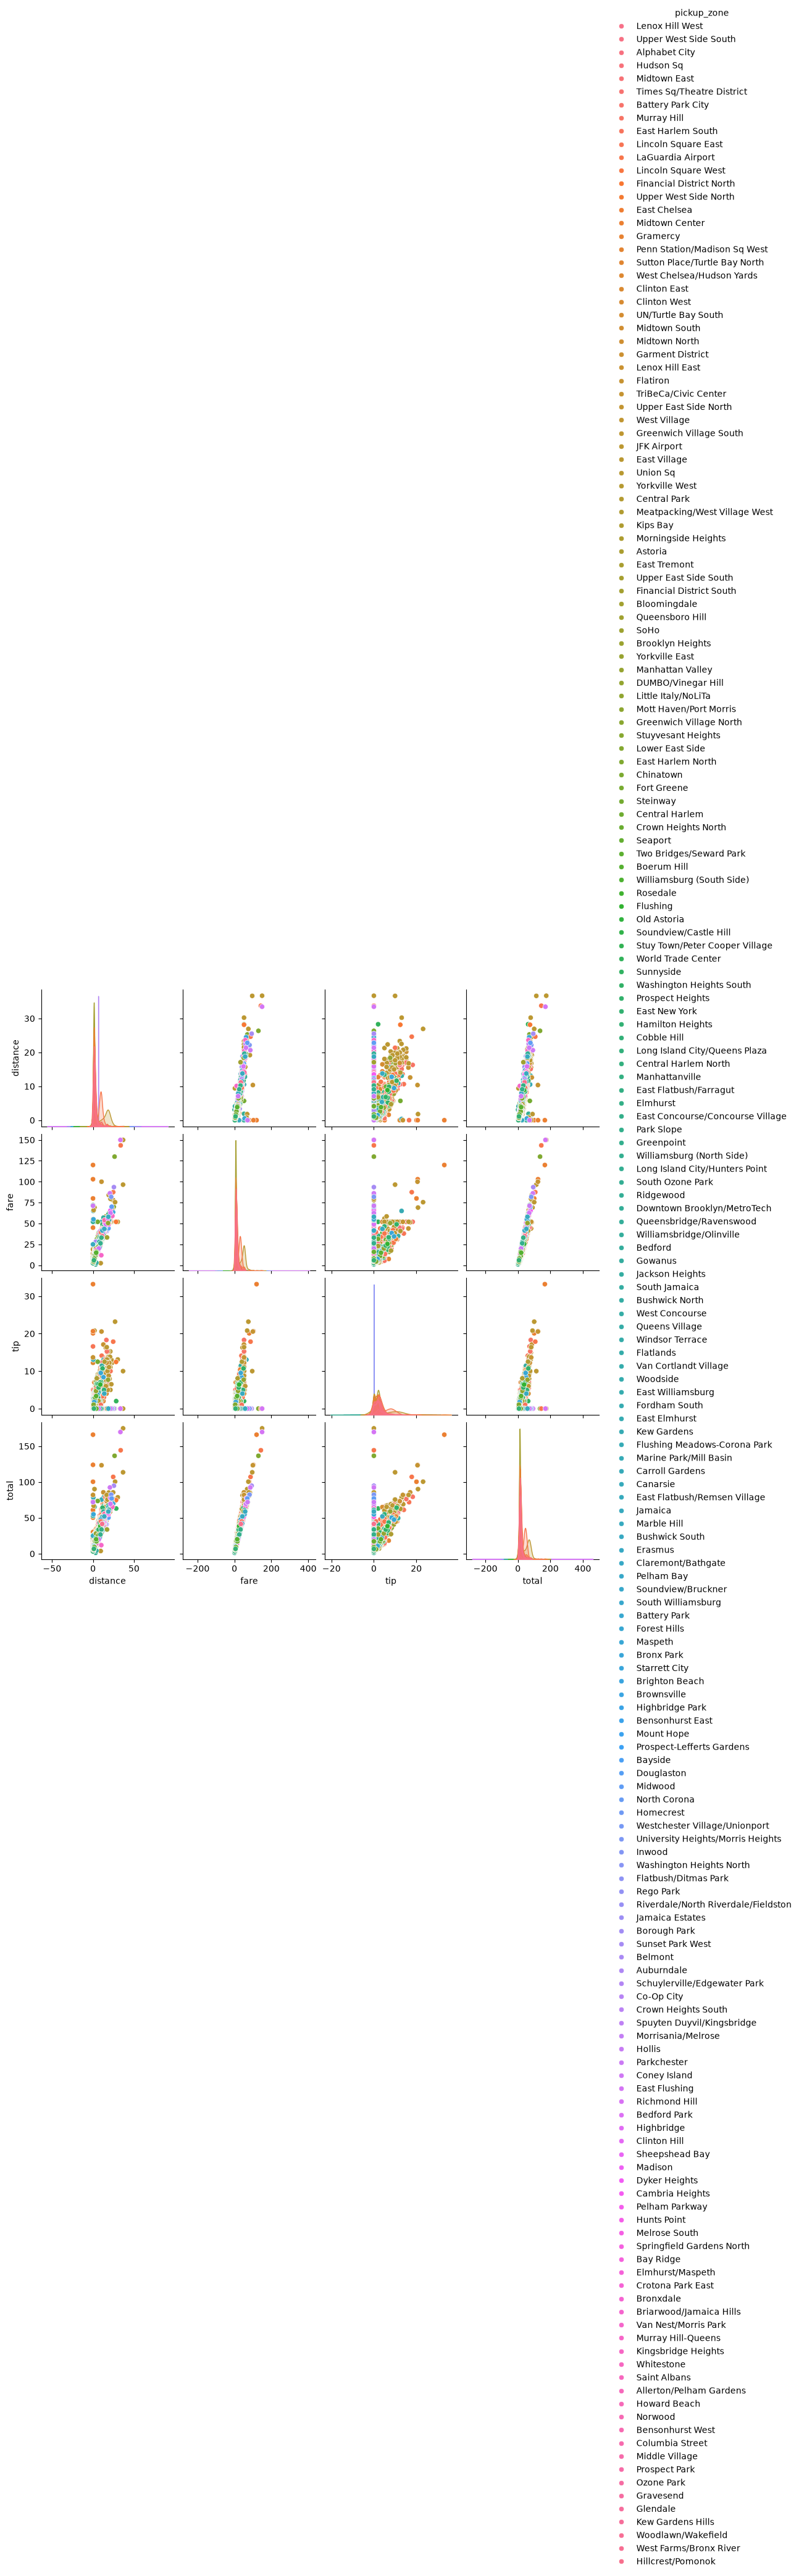

In [23]:
sns.pairplot(
    df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)

plt.show()

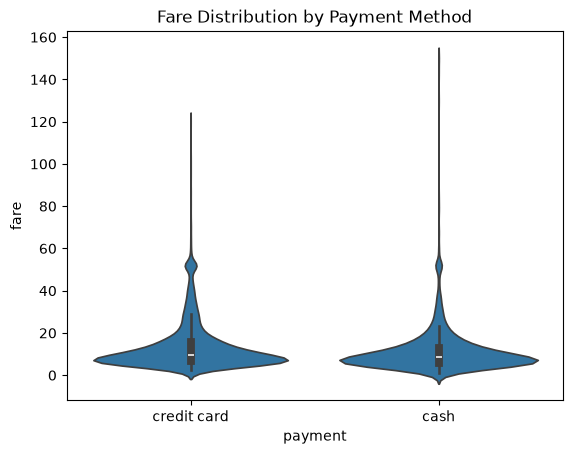

In [22]:
sns.violinplot(data=df, x="payment", y="fare")

plt.title("Fare Distribution by Payment Method")
plt.show()